# Distributed Optical PNNs in Multi-Span Coherent QPSK Links

This notebook investigates the performance of **Distributed Optical Photonic Neural Networks (PNNs)** in a multi-span EDFA-amplified coherent optical link.

### System Architecture
Rather than placing a single PNN at the receiver, an optical PNN is deployed **in-line at each fiber span**:
$$\text{Transmitter} \longrightarrow \left[ \boxed{\text{Fiber Span}} \longrightarrow \boxed{\text{Optical PNN}_k} \longrightarrow \boxed{\text{EDFA}_k} \right]_{k=1}^{N_{\text{spans}}} \longrightarrow \text{Receiver Stage} \longrightarrow \text{Coherent Rx} \longrightarrow (\text{Optional Digital CDC})$$

In each span $k$:
1. The optical signal propagates through $50\text{ km}$ of standard single-mode fiber (accumulating chromatic dispersion, passive loss, and nonlinear Kerr phase shift).
2. The optical field passes through **Optical PNN $k$** (a passive mesh of tunable optical delays and phase shifters) which performs distributed analog optical dispersion equalization.
3. An **in-line EDFA** amplifies the signal to compensate the span's passive loss before launching into the next span.

### Sequential Stage-wise (Span-by-Span) Training
To avoid the curse of dimensionality of a joint $640$-parameter PSO over 20 spans, training is performed **stage-wise from span 1 to span $N_{\text{spans}}$**:
* Each PNN $k$ optimizes its $2 \times N_{\text{channels}}$ weights ($32$ parameters) based on the optical signal at the end of span $k$.
* The fiber propagation up to span $k$ is computed once; the PSO optimizes the local PNN $k$ weights rapidly.
* Once trained, PNN $k$'s weights are fixed, the equalized field passes through EDFA $k$, and the process advances to span $k+1$.

### Configurable Objective Function: EVM vs. BER
The PSO optimizer can be configured to minimize either **Error Vector Magnitude (EVM)** or **Bit Error Rate (BER)**:
* `PSO_OBJECTIVE = 'EVM'` (Recommended): Provides a continuous, smooth objective surface with implicit gradients that guide particles even when BER is zero or saturated.
* `PSO_OBJECTIVE = 'BER'`: Directly targets bit decision errors on the training sequence.

### Four Comparative Scenarios Evaluated
1. **No PNN, no CDC**: Baseline uncompensated multi-span link.
2. **No PNN, with CDC**: Baseline link with conventional digital Chromatic Dispersion Compensation at the receiver.
3. **Distributed PNNs, no CDC**: Multi-span link with distributed PNNs and no digital CDC at the receiver (testing if in-line optical PNNs can eliminate digital CDC).
4. **Distributed PNNs + CDC**: Multi-span link with distributed PNNs (trained jointly with CDC) plus digital CDC at the receiver.


In [1]:
from pathlib import Path
import sys
import json
import time
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dsp.transmitter import (
    ElectricalFilterParams,
    IQMZMParams,
    generate_qpsk_symbols,
    modulate_optical_signal,
)
from src.dsp.fiber import FiberParams, fibra_monomodo
from src.utils.edfa import EDFAIdeal
from src.dsp.noise_models import generate_wiener_phase_noise
from src.dsp.receiver import coherent_detection, cd_compensation, sample_to_symbols, demap_qpsk
from src.utils.metrics import calculate_ber, calculate_evm
from src.utils.pnn_model import PhotonicNeuralNetwork
from scripts.optimize_pnn_pso import particle_swarm_optimize

FIG_DIR = PROJECT_ROOT / 'artifacts' / 'figures' / 'mult_pnn_edfa_evm'
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS_DIR = PROJECT_ROOT / 'artifacts' / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f'Project root: {PROJECT_ROOT}')
print(f'Figures destination: {FIG_DIR}')


Project root: D:\gits\PHOTONICS_2026\Codigos\python\pnn_coerente
Figures destination: D:\gits\PHOTONICS_2026\Codigos\python\pnn_coerente\artifacts\figures\mult_pnn_edfa_evm


## 1. Parameters and Link Configuration

* `PSO_OBJECTIVE`: Selects the training fitness function (`'EVM'` or `'BER'`).
* `SPAN_LENGTH_KM`: Length of each individual fiber span ($50.0\text{ km}$).
* `DISTANCE_SWEEP_MAX_KM`: Maximum total distance ($1000.0\text{ km}$, corresponding to $20$ spans).
* `PNN_NUM_CHANNELS`: Number of delay/phase branches in each PNN ($16$ channels = $32$ parameters per PNN).


In [2]:
# Objective function selector: 'EVM' or 'BER'
PSO_OBJECTIVE = 'EVM'  # Select 'EVM' (recommended) or 'BER'
CORRECT_PHASE_ROTATION = True

# Simulation parameters
NUM_SYMBOLS = 2**12
SPS = 8
SYMBOL_RATE = 10e9
WAVELENGTH = 1550e-9
DT = 1.0 / (SPS * SYMBOL_RATE)

# Span and link geometry
SPAN_LENGTH_KM = 50.0
DISTANCE_SWEEP_MAX_KM = 1000.0
DISTANCE_NONLINEAR_KM = 1000.0
NUM_STEPS_PER_SPAN = 50

if SPAN_LENGTH_KM <= 0:
    raise ValueError('SPAN_LENGTH_KM must be positive.')
if DISTANCE_SWEEP_MAX_KM % SPAN_LENGTH_KM != 0:
    raise ValueError('DISTANCE_SWEEP_MAX_KM must be an integer multiple of SPAN_LENGTH_KM.')
if DISTANCE_NONLINEAR_KM % SPAN_LENGTH_KM != 0:
    raise ValueError('DISTANCE_NONLINEAR_KM must be an integer multiple of SPAN_LENGTH_KM.')

DISTANCES_KM = np.arange(
    SPAN_LENGTH_KM, DISTANCE_SWEEP_MAX_KM + SPAN_LENGTH_KM, SPAN_LENGTH_KM
)
N_SPANS_MAX = int(round(DISTANCE_SWEEP_MAX_KM / SPAN_LENGTH_KM))

# Terminal EDFA and target received power
RX_EDFA_GAIN_DB = 20.0
RX_TARGET_DBM = 0.0

# Launch power and linewidths
LUNCH_POWER_DBM = 0.0
TX_POWER_DISPERSION_DBM = 0.0
POWER_SWEEP_DBM = np.arange(-20.0, 20.1, 2.0)
LINEWIDTHS_HZ = np.array([0.0, 100e3, 1e6])

# Physical fiber parameters (SMF-28 profile)
FIBER_PARAMS = FiberParams(
    alpha_db=0.2,
    d_1550=16.0,
    slope_s=0.09,
    n2=3.2e-20,
    a_eff=70e-12,
    )
IQ_PARAMS = IQMZMParams(electrical_response=False)
EDFA_MODEL = EDFAIdeal
FILTER_PARAMS = ElectricalFilterParams(
    tipo='gaussiano',
    largura_banda_hz=2 * SYMBOL_RATE,
    ordem=7,
)
MODULATOR = 'iq_mzm'

# PNN Architecture & PSO Hyperparameters
PNN_NUM_CHANNELS = 8
PNN_BASE_DELAY_PS = 25.0
PNN_NORMALIZE_POWER = True
PNN_TRAIN_SYMBOLS = 2**10
PNN_TRAIN_SEED = 20261101
PNN_SWARM_SIZE = 30
PNN_ITERATIONS = 50

BER_PLOT_FLOOR = 1.0 / (2.0 * (NUM_SYMBOLS * 2))

print(f'Active PSO Objective: {PSO_OBJECTIVE}')
print(f'Span length: {SPAN_LENGTH_KM:g} km | Total spans: {N_SPANS_MAX}')
print(f'Distance sweep: {DISTANCES_KM[0]:g} km to {DISTANCES_KM[-1]:g} km ({len(DISTANCES_KM)} points)')
print(f'Linewidths: {LINEWIDTHS_HZ} Hz')


Active PSO Objective: EVM
Span length: 50 km | Total spans: 20
Distance sweep: 50 km to 1000 km (20 points)
Linewidths: [      0.  100000. 1000000.] Hz


## 2. Distributed Propagation and Metrics Calculation Functions

Here we implement the distributed multi-span propagation pipeline:
* `propagate_single_span()`: Propagates the optical field through one fiber span of length `SPAN_LENGTH_KM`.
* `propagate_distributed_link()`: Executes the chain of spans with in-line PNNs and EDFAs.
* `receiver_edfa_and_attenuator()`: Fixed-gain terminal amplification and variable optical attenuator setting receiver power to `RX_TARGET_DBM`.
* `compute_objective_value()`: Computes either EVM (%) or BER for the PSO cost function.
* `detect_and_evaluate()`: Performs coherent detection, optional digital CDC, and returns both BER and EVM.


In [3]:
def mean_power_dbm(field):
    """Mean optical envelope power in dBm."""
    power_w = np.mean(np.abs(field) ** 2)
    return 10.0 * np.log10(power_w / 1e-3 + 1e-30)



def propagate_single_span(field_in, t, span_length_km, include_nonlinearity, num_steps=NUM_STEPS_PER_SPAN):
    """Propagates the field through a single fiber span."""
    regime = 1 if include_nonlinearity else 0
    field_out, _, _ = fibra_monomodo(
        t,
        np.asarray(field_in, dtype=complex),
        wavelength=WAVELENGTH,
        t0=1.0 / SYMBOL_RATE,
        length_km=span_length_km,
        regime=regime,
        params=FIBER_PARAMS,
        num_steps=num_steps,
    )
    return field_out


def propagate_distributed_link(
    field_in, t, n_spans, pnn_chain=None, include_nonlinearity=False,
    span_length_km=SPAN_LENGTH_KM, num_steps_per_span=NUM_STEPS_PER_SPAN
):
    """Propagates through n_spans, applying [Fiber -> PNN_k -> EDFA_k] in each span.
    
    Parameters
    ----------
    field_in : complex ndarray
        Optical field launched into the link.
    t : ndarray
        Time grid.
    n_spans : int
        Number of spans to propagate.
    pnn_chain : list of dict, optional
        List of trained PNN weights dictionaries for spans 0 to n_spans-1.
        If None, no PNNs are applied (baseline link).
    include_nonlinearity : bool
        Whether to enable Kerr nonlinear phase shift in SSFM.
    """
    field = np.asarray(field_in, dtype=complex).copy()
    span_loss_db = FIBER_PARAMS.alpha_db * span_length_km

    
    model = None
    if pnn_chain is not None:
        model = PhotonicNeuralNetwork(
            num_channels=PNN_NUM_CHANNELS,
            base_delay_ps=PNN_BASE_DELAY_PS,
            normalize_power=PNN_NORMALIZE_POWER,
            responsivity=1.0,
        )

    for k in range(n_spans):
        # 1. Fiber propagation
        field = propagate_single_span(
            field, t, span_length_km, include_nonlinearity, num_steps=num_steps_per_span
        )
        
        # 2. Optical PNN equalization for span k (if provided)
        if pnn_chain is not None and k < len(pnn_chain) and pnn_chain[k] is not None:
            weights = pnn_chain[k]
            model.set_weights(weights['amplitude_weights'], weights['phase_weights'])
            field_power_befor_pnn = mean_power_dbm(field)
            _, field = model.forward(field, dt_s=DT, return_optical_field=True)
            field_power_after_pnn = mean_power_dbm(field)
            if field_power_after_pnn > field_power_befor_pnn:
                raise ValueError('PNN is amplifying the singnal!\nSome thing is wrong with the PNN model or the input signal.')
            pnn_loss_db = field_power_befor_pnn - field_power_after_pnn
            inline_edfa = EDFA_MODEL(gain_db=(span_loss_db + pnn_loss_db))
        else:
            inline_edfa = EDFA_MODEL(gain_db=span_loss_db)
        # 3. In-line EDFA compensates span and PNN loss
        field = inline_edfa.amplify(field)

    return field


def receiver_edfa_and_attenuator(field, target_dbm=RX_TARGET_DBM, edfa_gain_db=RX_EDFA_GAIN_DB):
    """Terminal EDFA and variable optical attenuator setting received power."""
    receiver_edfa = EDFA_MODEL(gain_db=edfa_gain_db)
    amplified = receiver_edfa.amplify(field)
    power_after_edfa_dbm = mean_power_dbm(amplified)
    power_before_edfa_dbm = mean_power_dbm(field)
    attenuation_db = power_after_edfa_dbm - target_dbm
    if attenuation_db < -1e-9:
        raise ValueError(f'Power before EDFA is {power_before_edfa_dbm} dBm.\nPower after EDFA is {power_after_edfa_dbm} dBm.\nTerminal EDFA gain is insufficient to reach target power of {target_dbm} dBm.')
    attenuation_db = max(0.0, attenuation_db)
    received = amplified * 10.0 ** (-attenuation_db / 20.0)
    return received, attenuation_db, power_after_edfa_dbm


def compute_objective_value(rx_symbols, bits_ref, objective_type=PSO_OBJECTIVE):
    """Calculates the cost function for PSO (either EVM or BER)."""
    if objective_type.upper() == 'EVM':
        return float(calculate_evm(rx_symbols, correct_phase_rotation=CORRECT_PHASE_ROTATION))
    elif objective_type.upper() == 'BER':
        detected_bits = demap_qpsk(rx_symbols)
        n_bits = min(len(bits_ref), len(detected_bits))
        return float(calculate_ber(bits_ref[:n_bits], detected_bits[:n_bits]))
    else:
        raise ValueError(f"Unknown objective_type: {objective_type}")


def detect_and_evaluate(field_rx, phase_lo, bits_ref, symbols_ref, dt_val=DT, cdc_distance_km=None):
    """Coherent detection, optional digital CDC, and calculation of both BER and EVM."""
    r_bb = coherent_detection(field_rx, phase_lo=phase_lo)
    if cdc_distance_km is not None and cdc_distance_km > 0.0:
        r_bb = cd_compensation(
            r_bb, dt=dt_val, length_km=float(cdc_distance_km), dispersion_d=FIBER_PARAMS.d_1550
        )
    rx_symbols = sample_to_symbols(r_bb, sps=SPS)
    n_sym = min(len(symbols_ref), len(rx_symbols))
    evm_val = float(calculate_evm(rx_symbols[:n_sym], correct_phase_rotation=CORRECT_PHASE_ROTATION))
    detected_bits = demap_qpsk(rx_symbols)
    n_bits = min(len(bits_ref), len(detected_bits))
    ber_val = float(calculate_ber(bits_ref[:n_bits], detected_bits[:n_bits]))
    return ber_val, evm_val, rx_symbols[:n_sym]


## 3. Signal Generation and Phase Noise Realizations

Independent training ($2^{10}$ symbols) and evaluation ($2^{12}$ symbols) QPSK frames are generated with an IQ Mach-Zehnder Modulator and pulse shaping.
Wiener phase noise realizations are precomputed for the three linewidths ($0\text{ Hz}$, $100\text{ kHz}$, $1\text{ MHz}$).


In [4]:
# Training and testing sequences
train_symbols, train_bits = generate_qpsk_symbols(PNN_TRAIN_SYMBOLS, seed=PNN_TRAIN_SEED)
test_symbols, test_bits = generate_qpsk_symbols(NUM_SYMBOLS, seed=PNN_TRAIN_SEED + 1)

# Optical modulation
u_train_0dbm, t_train, dt_train = modulate_optical_signal(
    train_symbols,
    sps=SPS,
    launch_power_dbm=LUNCH_POWER_DBM,
    symbol_rate=SYMBOL_RATE,
    modulator=MODULATOR,
    iq_params=IQ_PARAMS,
    filter_params=FILTER_PARAMS,
    plot_filter=False,
    n_plot=0,
)

u_test_0dbm, t_test, dt_test = modulate_optical_signal(
    test_symbols,
    sps=SPS,
    launch_power_dbm=LUNCH_POWER_DBM,
    symbol_rate=SYMBOL_RATE,
    modulator=MODULATOR,
    iq_params=IQ_PARAMS,
    filter_params=FILTER_PARAMS,
    plot_filter=False,
    n_plot=0,
)

if not np.isclose(dt_train, DT) or not np.isclose(dt_test, DT):
    raise ValueError('Sampling interval mismatch with symbol rate and SPS.')

# Phase noise realizations
phase_noise_test = {}
phase_noise_train = {}
for idx, linewidth_hz in enumerate(LINEWIDTHS_HZ):
    lw_key = float(linewidth_hz)
    phase_noise_train[lw_key] = {
        'tx': generate_wiener_phase_noise(len(t_train), DT, lw_key, seed=PNN_TRAIN_SEED + 100 + 2 * idx),
        'lo': generate_wiener_phase_noise(len(t_train), DT, lw_key, seed=PNN_TRAIN_SEED + 101 + 2 * idx),
    }
    phase_noise_test[lw_key] = {
        'tx': generate_wiener_phase_noise(len(t_test), DT, lw_key, seed=PNN_TRAIN_SEED + 200 + 2 * idx),
        'lo': generate_wiener_phase_noise(len(t_test), DT, lw_key, seed=PNN_TRAIN_SEED + 201 + 2 * idx),
    }

print(f'Training symbols: {len(train_symbols)} | Test symbols: {len(test_symbols)}')
print(f'Sampling period DT: {DT*1e12:.3f} ps (Sampling frequency: {1.0/DT/1e9:.1f} GHz)')


Training symbols: 1024 | Test symbols: 4096
Sampling period DT: 12.500 ps (Sampling frequency: 80.0 GHz)


## 4. Stage-wise (Span-by-Span) Training of the Distributed PNN Chains

In this section, we train the two distributed PNN chains of length $N_{\text{spans}} = 20$ (one PNN per $50\text{ km}$ span):
1. **`pnn_chains_no_cdc`**: Each PNN $k$ is optimized to compensate span $k$'s distortion **without digital CDC** (seeking standalone optical equalization).
2. **`pnn_chains_joint_cdc`**: Each PNN $k$ is optimized **jointly with digital CDC** for the cumulative link distance up to that span ($d_k = k \times 50\text{ km}$).

### Optimization Efficiency
Because span $k$ depends only on the output of span $k-1$:
1. The optical field is propagated through fiber span $k$ **once**.
2. Inside the PSO objective loop, only the local PNN $k$ forward pass, coherent detection, and fitness calculation are executed (taking only milliseconds per particle).
3. The best weights are applied, the field is amplified by EDFA $k$, and the resulting field enters span $k+1$.


In [5]:
pnn_bounds = [(0.0, 1.0)] * PNN_NUM_CHANNELS + [(-np.pi, np.pi)] * PNN_NUM_CHANNELS
pnn_model_trainer = PhotonicNeuralNetwork(
    num_channels=PNN_NUM_CHANNELS,
    base_delay_ps=PNN_BASE_DELAY_PS,
    normalize_power=PNN_NORMALIZE_POWER,
    responsivity=1.0,
)

# Dictionaries storing the trained PNN chains: [scenario][linewidth_key] -> list of span weights

# --- Fitness "CDC only" (sem PNN), nas mesmas condições do treinamento ---
cdc_only_fitness = {}
trained_chains_no_cdc = {}
trained_chains_joint_cdc = {}
training_histories = {'no_cdc': {}, 'joint_cdc': {}}

span_loss_db = FIBER_PARAMS.alpha_db * SPAN_LENGTH_KM
inline_edfa = EDFA_MODEL(gain_db=span_loss_db)

total_train_start = time.time()
print(f'Starting sequential stage-wise training ({N_SPANS_MAX} spans per chain)...')
print(f'Optimizer objective: {PSO_OBJECTIVE}\n')

for lw_idx, linewidth_hz in enumerate(LINEWIDTHS_HZ):
    lw_key = float(linewidth_hz)
    p_train = phase_noise_train[lw_key]


    field = (u_train_0dbm * 10.0 ** (TX_POWER_DISPERSION_DBM / 20.0)) * np.exp(1j * p_train['tx'])
    fitness_list = []

    for span_idx in range(N_SPANS_MAX):
        cum_dist_km = (span_idx + 1) * SPAN_LENGTH_KM

        # Fibra + EDFA inline (sem PNN)
        field = propagate_single_span(field, t_train, SPAN_LENGTH_KM, include_nonlinearity=False)
        field = inline_edfa.amplify(field)

        # Detecção coerente + CDC digital para a distância acumulada
        r = coherent_detection(field, phase_lo=p_train['lo'])
        r_comp = cd_compensation(r, dt=DT, length_km=cum_dist_km, dispersion_d=FIBER_PARAMS.d_1550)
        rx_syms = sample_to_symbols(r_comp, sps=SPS)
        fitness_list.append(
            compute_objective_value(rx_syms[:len(train_symbols)], train_bits, PSO_OBJECTIVE)
        )

    cdc_only_fitness[lw_key] = fitness_list


    print(f'=== Training Distributed PNN Chains for Linewidth = {linewidth_hz/1e3:g} kHz ===')
    
    # -------------------------------------------------------------
    # Chain 1: Standalone Distributed PNNs (Trained WITHOUT CDC)
    # -------------------------------------------------------------
    chain_no_cdc = []
    histories_no_cdc = []
    
    # Initial field entering Span 1
    current_field = (u_train_0dbm * 10.0 ** (TX_POWER_DISPERSION_DBM / 20.0)) * np.exp(1j * p_train['tx'])

    for span_idx in range(N_SPANS_MAX):
        span_num = span_idx + 1
        cum_dist_km = span_num * SPAN_LENGTH_KM
        
        # Propagate through fiber span k (computed once)
        field_after_fiber = propagate_single_span(
            current_field, t_train, SPAN_LENGTH_KM, include_nonlinearity=False
        )
        
        # Define PSO objective for PNN k
        def span_objective_no_cdc(position):
            pnn_model_trainer.set_weights(position[:PNN_NUM_CHANNELS], position[PNN_NUM_CHANNELS:])
            _, opt_field = pnn_model_trainer.forward(field_after_fiber, dt_s=DT, return_optical_field=True)
            r = coherent_detection(opt_field, phase_lo=p_train['lo'])
            rx_syms = sample_to_symbols(r, sps=SPS)
            return compute_objective_value(rx_syms[:len(train_symbols)], train_bits, PSO_OBJECTIVE)
            
        pso_seed = PNN_TRAIN_SEED + 10000 * lw_idx + 100 * span_idx
        pso_res = particle_swarm_optimize(
            span_objective_no_cdc,
            pnn_bounds,
            swarm_size=PNN_SWARM_SIZE,
            max_iterations=PNN_ITERATIONS,
            periodic_dimensions=range(PNN_NUM_CHANNELS, 2 * PNN_NUM_CHANNELS),
            seed=pso_seed,
        )
        
        span_record = {
            'span_index': span_idx,
            'span_num': span_num,
            'cum_distance_km': cum_dist_km,
            'amplitude_weights': pso_res['amplitude_weights'].copy(),
            'phase_weights': pso_res['phase_weights'].copy(),
            'best_fitness': float(pso_res['best_fitness']),
            'evaluations': int(pso_res['evaluations']),
        }
        chain_no_cdc.append(span_record)
        histories_no_cdc.append(pso_res['best_fitness_history'])
        
        # Advance field through best PNN k and EDFA k for next span
        pnn_model_trainer.set_weights(pso_res['amplitude_weights'], pso_res['phase_weights'])
        _, opt_field_best = pnn_model_trainer.forward(field_after_fiber, dt_s=DT, return_optical_field=True)
        current_field = inline_edfa.amplify(opt_field_best)
        
    trained_chains_no_cdc[lw_key] = chain_no_cdc
    training_histories['no_cdc'][lw_key] = histories_no_cdc
    print(f'  [No CDC] Span {N_SPANS_MAX} ({DISTANCE_SWEEP_MAX_KM:g} km) Final Stage Fitness ({PSO_OBJECTIVE}): {chain_no_cdc[-1]["best_fitness"]:.4f}')

    # -------------------------------------------------------------
    # Chain 2: Distributed PNNs Trained JOINTLY WITH CDC
    # -------------------------------------------------------------
    chain_joint_cdc = []
    histories_joint_cdc = []
    
    current_field_cdc = (u_train_0dbm * 10.0 ** (TX_POWER_DISPERSION_DBM / 20.0)) * np.exp(1j * p_train['tx'])
    
    for span_idx in range(N_SPANS_MAX):
        span_num = span_idx + 1
        cum_dist_km = span_num * SPAN_LENGTH_KM
        
        field_after_fiber_cdc = propagate_single_span(
            current_field_cdc, t_train, SPAN_LENGTH_KM, include_nonlinearity=False
        )
        
        # Define PSO objective for PNN k with digital CDC compensation for cumulative distance
        def span_objective_joint_cdc(position):
            pnn_model_trainer.set_weights(position[:PNN_NUM_CHANNELS], position[PNN_NUM_CHANNELS:])
            _, opt_field = pnn_model_trainer.forward(field_after_fiber_cdc, dt_s=DT, return_optical_field=True)
            r = coherent_detection(opt_field, phase_lo=p_train['lo'])
            r_comp = cd_compensation(r, dt=DT, length_km=cum_dist_km, dispersion_d=FIBER_PARAMS.d_1550)
            rx_syms = sample_to_symbols(r_comp, sps=SPS)
            return compute_objective_value(rx_syms[:len(train_symbols)], train_bits, PSO_OBJECTIVE)
            
        pso_seed_joint = PNN_TRAIN_SEED + 50000 + 10000 * lw_idx + 100 * span_idx
        pso_res_joint = particle_swarm_optimize(
            span_objective_joint_cdc,
            pnn_bounds,
            swarm_size=PNN_SWARM_SIZE,
            max_iterations=PNN_ITERATIONS,
            periodic_dimensions=range(PNN_NUM_CHANNELS, 2 * PNN_NUM_CHANNELS),
            seed=pso_seed_joint,
        )
        
        span_record_joint = {
            'span_index': span_idx,
            'span_num': span_num,
            'cum_distance_km': cum_dist_km,
            'amplitude_weights': pso_res_joint['amplitude_weights'].copy(),
            'phase_weights': pso_res_joint['phase_weights'].copy(),
            'best_fitness': float(pso_res_joint['best_fitness']),
            'evaluations': int(pso_res_joint['evaluations']),
        }
        chain_joint_cdc.append(span_record_joint)
        histories_joint_cdc.append(pso_res_joint['best_fitness_history'])
        
        pnn_model_trainer.set_weights(pso_res_joint['amplitude_weights'], pso_res_joint['phase_weights'])
        _, opt_field_joint_best = pnn_model_trainer.forward(field_after_fiber_cdc, dt_s=DT, return_optical_field=True)
        current_field_cdc = inline_edfa.amplify(opt_field_joint_best)
        
    trained_chains_joint_cdc[lw_key] = chain_joint_cdc
    training_histories['joint_cdc'][lw_key] = histories_joint_cdc
    print(f'  [Joint CDC] Span {N_SPANS_MAX} ({DISTANCE_SWEEP_MAX_KM:g} km) Final Stage Fitness ({PSO_OBJECTIVE}): {chain_joint_cdc[-1]["best_fitness"]:.4f}')

print(f'\nTotal training duration: {(time.time() - total_train_start)/60:.2f} minutes.')

# Save models to JSON
def _chain_to_serializable(chains):
    """Converte {linewidth: [span_record, ...]} em estruturas compatíveis com JSON."""
    out = {}
    for lw_key, chain in chains.items():
        out[str(lw_key)] = [
            {
                k: (v.tolist() if isinstance(v, np.ndarray)
                    else v.item() if isinstance(v, np.generic)
                    else v)
                for k, v in rec.items()
            }
            for rec in chain
        ]
    return out

save_data = {
    'pso_objective': PSO_OBJECTIVE,
    'span_length_km': SPAN_LENGTH_KM,
    'n_spans': N_SPANS_MAX,
    'pnn_num_channels': PNN_NUM_CHANNELS,
    'trained_chains_no_cdc': _chain_to_serializable(trained_chains_no_cdc),
    'trained_chains_joint_cdc': _chain_to_serializable(trained_chains_joint_cdc),
}
with open(MODELS_DIR / 'pnn_mult_span_pso_treinamento.json', 'w') as f:
    json.dump(save_data, f, indent=2)
print(f'Distributed PNN chains saved to: {MODELS_DIR / "pnn_mult_span_pso_treinamento.json"}')


Starting sequential stage-wise training (20 spans per chain)...
Optimizer objective: EVM

=== Training Distributed PNN Chains for Linewidth = 0 kHz ===
  [No CDC] Span 20 (1000 km) Final Stage Fitness (EVM): 51.5821
  [Joint CDC] Span 20 (1000 km) Final Stage Fitness (EVM): 28.4574
=== Training Distributed PNN Chains for Linewidth = 100 kHz ===
  [No CDC] Span 20 (1000 km) Final Stage Fitness (EVM): 57.5684
  [Joint CDC] Span 20 (1000 km) Final Stage Fitness (EVM): 77.0480
=== Training Distributed PNN Chains for Linewidth = 1000 kHz ===
  [No CDC] Span 20 (1000 km) Final Stage Fitness (EVM): 65.1877
  [Joint CDC] Span 20 (1000 km) Final Stage Fitness (EVM): 80.3326

Total training duration: 1.47 minutes.
Distributed PNN chains saved to: D:\gits\PHOTONICS_2026\Codigos\python\pnn_coerente\artifacts\models\pnn_mult_span_pso_treinamento.json


## 5. Convergence and Training Fitness Across Spans

We inspect the final training fitness ($EVM$ or $BER$) achieved by the PSO at each span stage from $k=1$ to $k=20$ ($50\text{ km}$ to $1000\text{ km}$).


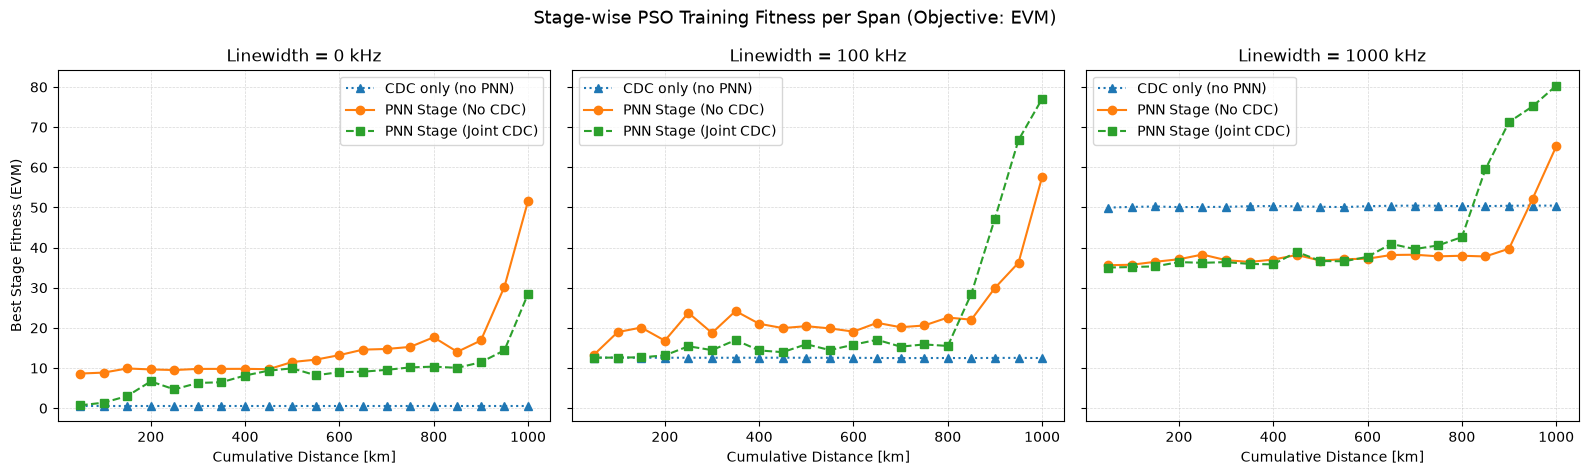

In [6]:

# --- Plot ---
fig, axes = plt.subplots(1, len(LINEWIDTHS_HZ), figsize=(16, 4.8), sharey=True)
span_numbers = np.arange(1, N_SPANS_MAX + 1)
distances_spans = span_numbers * SPAN_LENGTH_KM

for ax, linewidth_hz in zip(axes, LINEWIDTHS_HZ):
    lw_key = float(linewidth_hz)
    fitness_no_cdc = [rec['best_fitness'] for rec in trained_chains_no_cdc[lw_key]]
    fitness_joint_cdc = [rec['best_fitness'] for rec in trained_chains_joint_cdc[lw_key]]

    ax.plot(distances_spans, cdc_only_fitness[lw_key], '^:', color='tab:blue', label='CDC only (no PNN)')
    ax.plot(distances_spans, fitness_no_cdc, 'o-', color='tab:orange', label='PNN Stage (No CDC)')
    ax.plot(distances_spans, fitness_joint_cdc, 's--', color='tab:green', label='PNN Stage (Joint CDC)')
    ax.set_title(f'Linewidth = {linewidth_hz/1e3:g} kHz')
    ax.set_xlabel('Cumulative Distance [km]')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
    ax.legend(loc='best')

axes[0].set_ylabel(f'Best Stage Fitness ({PSO_OBJECTIVE})')
fig.suptitle(f'Stage-wise PSO Training Fitness per Span (Objective: {PSO_OBJECTIVE})', fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / 'mult_pnn_stage_fitness_per_span.png', dpi=250)
plt.show()

## 6. Analysis 1: Performance vs. Distance (50 km to 1000 km)

We evaluate the independent test sequence ($2^{12}$ symbols) across link distances from $50\text{ km}$ to $1000\text{ km}$ in $50\text{ km}$ steps (1 to 20 spans), comparing the four scenarios:
1. **No PNN, no CDC**
2. **No PNN, with CDC**
3. **Distributed PNNs, no CDC**
4. **Distributed PNNs + CDC**

Both **BER** and **EVM (%)** are recorded and plotted across distance for all three linewidths.


Running Analysis 1: Distance Sweep (50 km to 1000 km)...
Distance evaluation completed in 4.2 s.


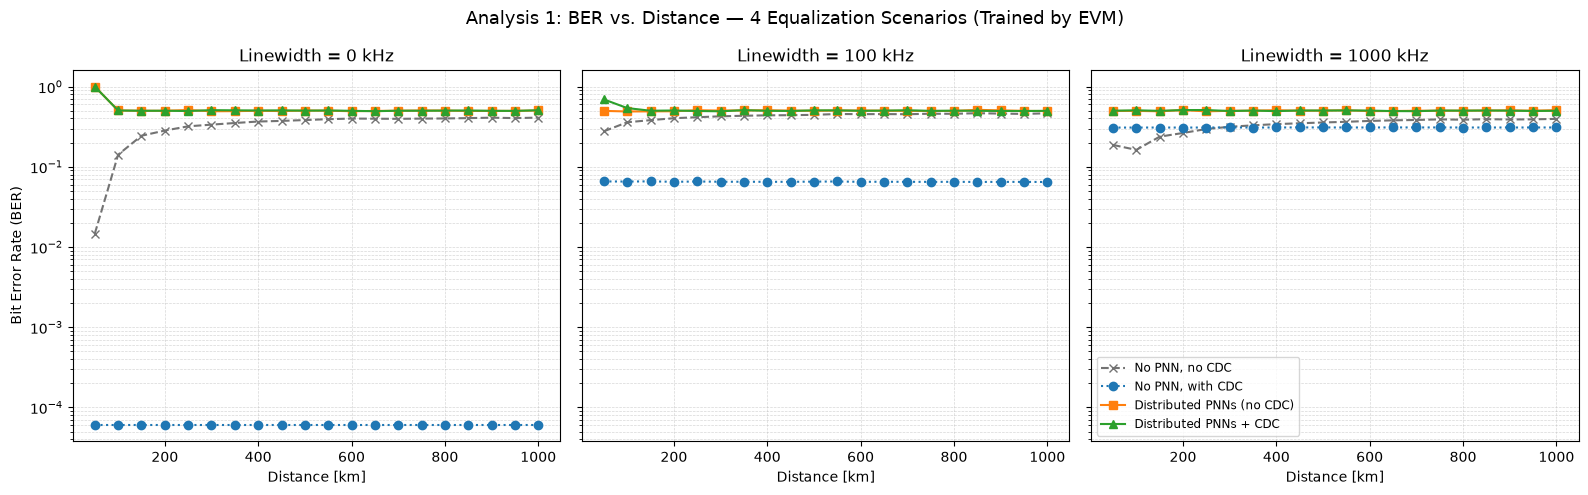

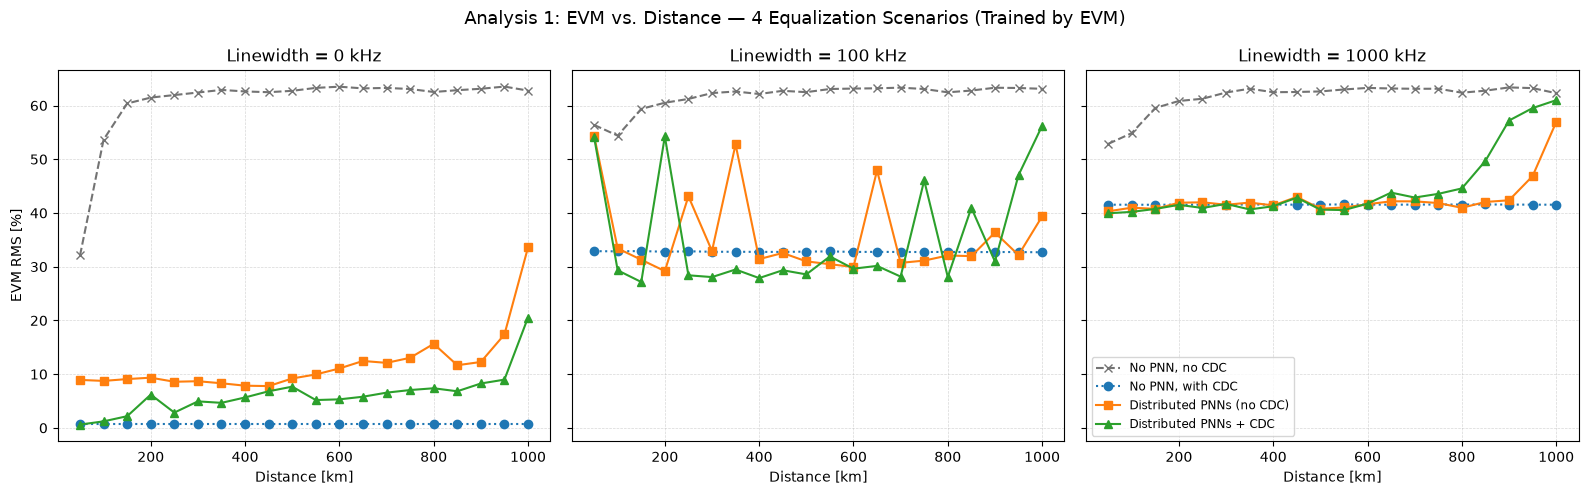

In [7]:
results_dist = {
    'ber_no_pnn_no_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'ber_no_pnn_with_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'ber_mult_pnn_no_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'ber_mult_pnn_joint_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'evm_no_pnn_no_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'evm_no_pnn_with_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'evm_mult_pnn_no_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'evm_mult_pnn_joint_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
}

constellations_1000km = {}

print('Running Analysis 1: Distance Sweep (50 km to 1000 km)...')
start_dist_eval = time.time()

for lw_idx, linewidth_hz in enumerate(LINEWIDTHS_HZ):
    lw_key = float(linewidth_hz)
    p_test = phase_noise_test[lw_key]
    field_test_tx = (u_test_0dbm * 10.0 ** (TX_POWER_DISPERSION_DBM / 20.0)) * np.exp(1j * p_test['tx'])
    
    chain_no_cdc = trained_chains_no_cdc[lw_key]
    chain_joint_cdc = trained_chains_joint_cdc[lw_key]
    
    for span_idx, distance_km in enumerate(DISTANCES_KM):
        n_spans = span_idx + 1
        
        # 1. Baseline: No PNN (Fiber + EDFA only)
        field_link_baseline = propagate_distributed_link(
            field_test_tx, t_test, n_spans=n_spans, pnn_chain=None, include_nonlinearity=False
        )
        field_rx_baseline, _, _ = receiver_edfa_and_attenuator(field_link_baseline)
        
        # 1a. No PNN, no CDC
        ber_1, evm_1, syms_1 = detect_and_evaluate(
            field_rx_baseline, p_test['lo'], test_bits, test_symbols, dt_val=DT, cdc_distance_km=None
        )
        results_dist['ber_no_pnn_no_cdc'][lw_key].append(ber_1)
        results_dist['evm_no_pnn_no_cdc'][lw_key].append(evm_1)
        
        # 1b. No PNN, with CDC
        ber_2, evm_2, syms_2 = detect_and_evaluate(
            field_rx_baseline, p_test['lo'], test_bits, test_symbols, dt_val=DT, cdc_distance_km=distance_km
        )
        results_dist['ber_no_pnn_with_cdc'][lw_key].append(ber_2)
        results_dist['evm_no_pnn_with_cdc'][lw_key].append(evm_2)
        
        # 2. Distributed PNNs (Trained without CDC) -> evaluated WITHOUT CDC
        sub_chain_no_cdc = chain_no_cdc[:n_spans]
        field_link_mult_pnn = propagate_distributed_link(
            field_test_tx, t_test, n_spans=n_spans, pnn_chain=sub_chain_no_cdc, include_nonlinearity=False
        )
        field_rx_mult_pnn, _, _ = receiver_edfa_and_attenuator(field_link_mult_pnn)
        ber_3, evm_3, syms_3 = detect_and_evaluate(
            field_rx_mult_pnn, p_test['lo'], test_bits, test_symbols, dt_val=DT, cdc_distance_km=None
        )
        results_dist['ber_mult_pnn_no_cdc'][lw_key].append(ber_3)
        results_dist['evm_mult_pnn_no_cdc'][lw_key].append(evm_3)
        
        # 3. Distributed PNNs (Trained jointly with CDC) -> evaluated WITH CDC
        sub_chain_joint_cdc = chain_joint_cdc[:n_spans]
        field_link_joint_pnn = propagate_distributed_link(
            field_test_tx, t_test, n_spans=n_spans, pnn_chain=sub_chain_joint_cdc, include_nonlinearity=False
        )
        field_rx_joint_pnn, _, _ = receiver_edfa_and_attenuator(field_link_joint_pnn)
        ber_4, evm_4, syms_4 = detect_and_evaluate(
            field_rx_joint_pnn, p_test['lo'], test_bits, test_symbols, dt_val=DT, cdc_distance_km=distance_km
        )
        results_dist['ber_mult_pnn_joint_cdc'][lw_key].append(ber_4)
        results_dist['evm_mult_pnn_joint_cdc'][lw_key].append(evm_4)
        
        if distance_km == DISTANCE_SWEEP_MAX_KM:
            constellations_1000km[lw_key] = {
                'no_pnn_no_cdc': syms_1,
                'no_pnn_with_cdc': syms_2,
                'mult_pnn_no_cdc': syms_3,
                'mult_pnn_joint_cdc': syms_4,
            }

print(f'Distance evaluation completed in {(time.time() - start_dist_eval):.1f} s.')

# Plot 1: BER vs Distance
fig, axes = plt.subplots(1, len(LINEWIDTHS_HZ), figsize=(16, 5), sharey=True)
for ax, linewidth_hz in zip(axes, LINEWIDTHS_HZ):
    lw_key = float(linewidth_hz)
    ax.semilogy(DISTANCES_KM, np.maximum(results_dist['ber_no_pnn_no_cdc'][lw_key], BER_PLOT_FLOOR), '--x', color='0.45', label='No PNN, no CDC')
    ax.semilogy(DISTANCES_KM, np.maximum(results_dist['ber_no_pnn_with_cdc'][lw_key], BER_PLOT_FLOOR), ':o', color='tab:blue', label='No PNN, with CDC')
    ax.semilogy(DISTANCES_KM, np.maximum(results_dist['ber_mult_pnn_no_cdc'][lw_key], BER_PLOT_FLOOR), '-s', color='tab:orange', label='Distributed PNNs (no CDC)')
    ax.semilogy(DISTANCES_KM, np.maximum(results_dist['ber_mult_pnn_joint_cdc'][lw_key], BER_PLOT_FLOOR), '-^', color='tab:green', label='Distributed PNNs + CDC')
    ax.set_title(f'Linewidth = {linewidth_hz/1e3:g} kHz')
    ax.set_xlabel('Distance [km]')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)

axes[0].set_ylabel('Bit Error Rate (BER)')
axes[-1].legend(loc='best', fontsize=8.5)
fig.suptitle(f'Analysis 1: BER vs. Distance — 4 Equalization Scenarios (Trained by {PSO_OBJECTIVE})', fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / 'mult_pnn_analise_1_ber_distancia_4_cenarios.png', dpi=250)
plt.show()

# Plot 2: EVM vs Distance
fig, axes = plt.subplots(1, len(LINEWIDTHS_HZ), figsize=(16, 5), sharey=True)
for ax, linewidth_hz in zip(axes, LINEWIDTHS_HZ):
    lw_key = float(linewidth_hz)
    ax.plot(DISTANCES_KM, results_dist['evm_no_pnn_no_cdc'][lw_key], '--x', color='0.45', label='No PNN, no CDC')
    ax.plot(DISTANCES_KM, results_dist['evm_no_pnn_with_cdc'][lw_key], ':o', color='tab:blue', label='No PNN, with CDC')
    ax.plot(DISTANCES_KM, results_dist['evm_mult_pnn_no_cdc'][lw_key], '-s', color='tab:orange', label='Distributed PNNs (no CDC)')
    ax.plot(DISTANCES_KM, results_dist['evm_mult_pnn_joint_cdc'][lw_key], '-^', color='tab:green', label='Distributed PNNs + CDC')
    ax.set_title(f'Linewidth = {linewidth_hz/1e3:g} kHz')
    ax.set_xlabel('Distance [km]')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)

axes[0].set_ylabel('EVM RMS [%]')
axes[-1].legend(loc='best', fontsize=8.5)
fig.suptitle(f'Analysis 1: EVM vs. Distance — 4 Equalization Scenarios (Trained by {PSO_OBJECTIVE})', fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / 'mult_pnn_analise_1_evm_distancia_4_cenarios.png', dpi=250)
plt.show()


## 7. Analysis 2: Performance vs. Launch Power (-20 to +20 dBm at 1000 km)

We evaluate the $1000\text{ km}$ link ($20$ spans) with the Kerr nonlinear effect enabled (`include_nonlinearity=True` in SSFM) across launch powers from $-20\text{ dBm}$ to $+20\text{ dBm}$.

The four scenarios are compared to assess nonlinear tolerance and whether distributed PNNs help mitigate nonlinear phase distortion alongside dispersion.


Running Analysis 2: Launch Power Sweep at 1000 km (Kerr enabled)...
Power evaluation completed in 482.8 s.


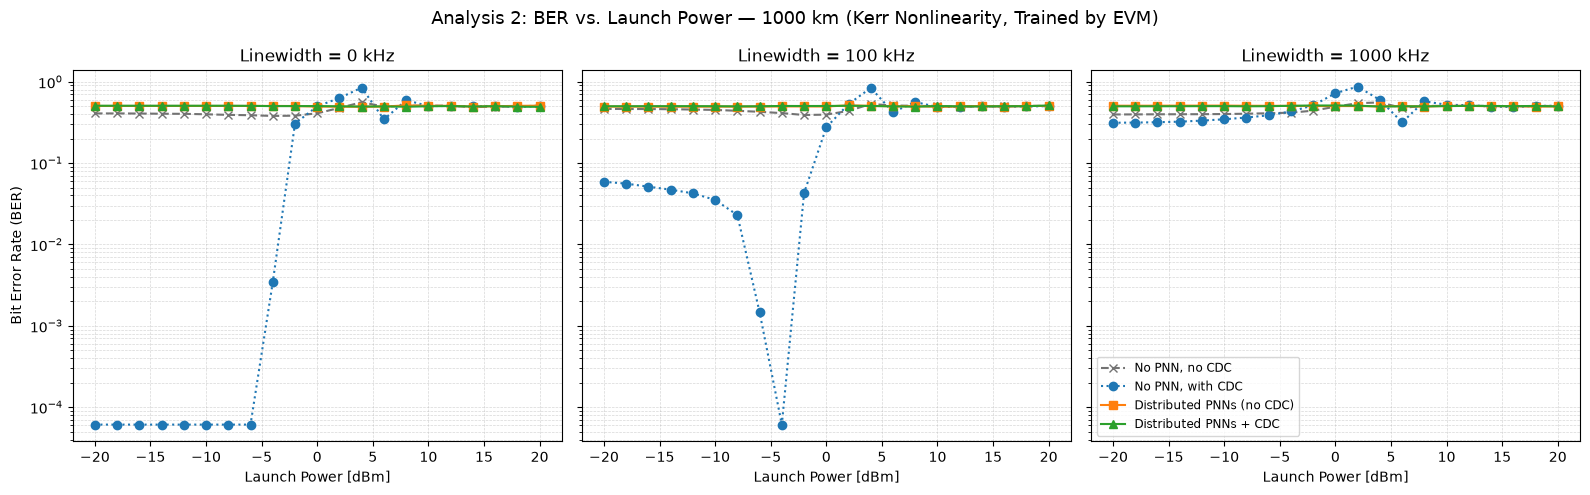

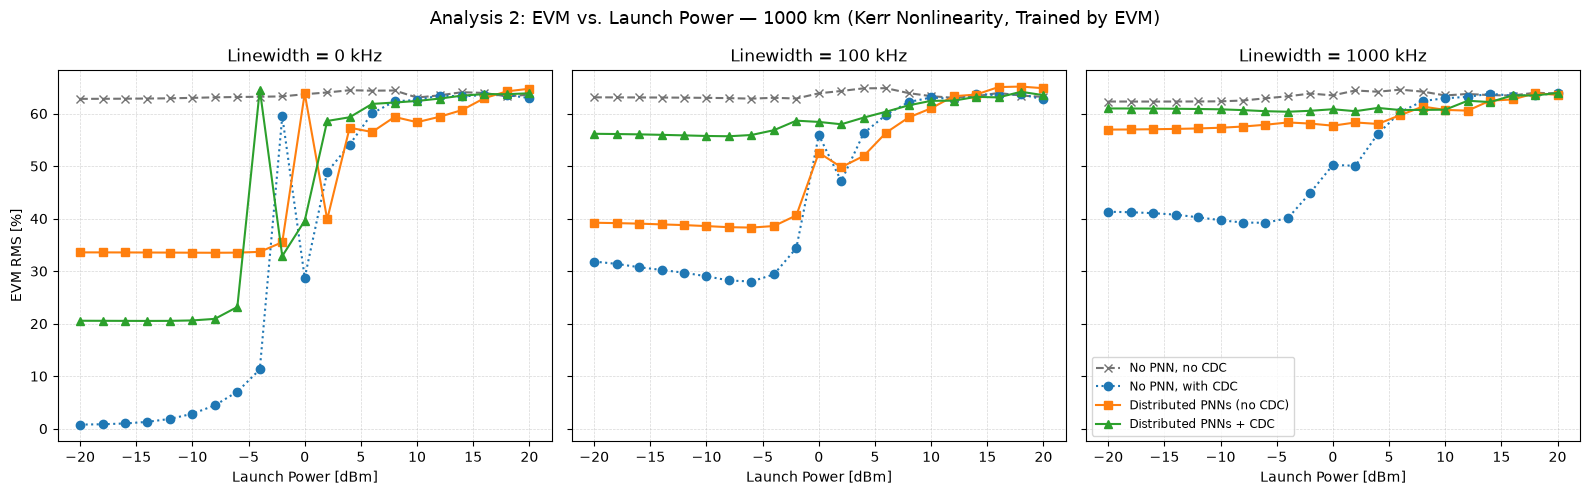

In [8]:
results_power = {
    'ber_no_pnn_no_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'ber_no_pnn_with_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'ber_mult_pnn_no_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'ber_mult_pnn_joint_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'evm_no_pnn_no_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'evm_no_pnn_with_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'evm_mult_pnn_no_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
    'evm_mult_pnn_joint_cdc': {float(lw): [] for lw in LINEWIDTHS_HZ},
}

print('Running Analysis 2: Launch Power Sweep at 1000 km (Kerr enabled)...')
start_power_eval = time.time()

for lw_idx, linewidth_hz in enumerate(LINEWIDTHS_HZ):
    lw_key = float(linewidth_hz)
    p_test = phase_noise_test[lw_key]
    
    chain_no_cdc = trained_chains_no_cdc[lw_key]
    chain_joint_cdc = trained_chains_joint_cdc[lw_key]
    
    for p_idx, launch_power_dbm in enumerate(POWER_SWEEP_DBM):
        p_val = float(launch_power_dbm - LUNCH_POWER_DBM)
        field_test_pwr = (u_test_0dbm * 10.0 ** (p_val / 20.0)) * np.exp(1j * p_test['tx'])
        
        # 1. Baseline (No PNN)
        field_link_baseline = propagate_distributed_link(
            field_test_pwr, t_test, n_spans=N_SPANS_MAX, pnn_chain=None, include_nonlinearity=True
        )
        field_rx_baseline, _, _ = receiver_edfa_and_attenuator(field_link_baseline)
        
        ber_1, evm_1, _ = detect_and_evaluate(
            field_rx_baseline, p_test['lo'], test_bits, test_symbols, dt_val=DT, cdc_distance_km=None
        )
        results_power['ber_no_pnn_no_cdc'][lw_key].append(ber_1)
        results_power['evm_no_pnn_no_cdc'][lw_key].append(evm_1)
        
        ber_2, evm_2, _ = detect_and_evaluate(
            field_rx_baseline, p_test['lo'], test_bits, test_symbols, dt_val=DT, cdc_distance_km=DISTANCE_NONLINEAR_KM
        )
        results_power['ber_no_pnn_with_cdc'][lw_key].append(ber_2)
        results_power['evm_no_pnn_with_cdc'][lw_key].append(evm_2)
        
        # 2. Distributed PNNs (No CDC)
        field_link_mult = propagate_distributed_link(
            field_test_pwr, t_test, n_spans=N_SPANS_MAX, pnn_chain=chain_no_cdc, include_nonlinearity=True
        )
        field_rx_mult, _, _ = receiver_edfa_and_attenuator(field_link_mult)
        ber_3, evm_3, _ = detect_and_evaluate(
            field_rx_mult, p_test['lo'], test_bits, test_symbols, dt_val=DT, cdc_distance_km=None
        )
        results_power['ber_mult_pnn_no_cdc'][lw_key].append(ber_3)
        results_power['evm_mult_pnn_no_cdc'][lw_key].append(evm_3)
        
        # 3. Distributed PNNs + CDC
        field_link_joint = propagate_distributed_link(
            field_test_pwr, t_test, n_spans=N_SPANS_MAX, pnn_chain=chain_joint_cdc, include_nonlinearity=True
        )
        field_rx_joint, _, _ = receiver_edfa_and_attenuator(field_link_joint)
        ber_4, evm_4, _ = detect_and_evaluate(
            field_rx_joint, p_test['lo'], test_bits, test_symbols, dt_val=DT, cdc_distance_km=DISTANCE_NONLINEAR_KM
        )
        results_power['ber_mult_pnn_joint_cdc'][lw_key].append(ber_4)
        results_power['evm_mult_pnn_joint_cdc'][lw_key].append(evm_4)

print(f'Power evaluation completed in {(time.time() - start_power_eval):.1f} s.')

# Plot 3: BER vs Power
fig, axes = plt.subplots(1, len(LINEWIDTHS_HZ), figsize=(16, 5), sharey=True)
for ax, linewidth_hz in zip(axes, LINEWIDTHS_HZ):
    lw_key = float(linewidth_hz)
    ax.semilogy(POWER_SWEEP_DBM, np.maximum(results_power['ber_no_pnn_no_cdc'][lw_key], BER_PLOT_FLOOR), '--x', color='0.45', label='No PNN, no CDC')
    ax.semilogy(POWER_SWEEP_DBM, np.maximum(results_power['ber_no_pnn_with_cdc'][lw_key], BER_PLOT_FLOOR), ':o', color='tab:blue', label='No PNN, with CDC')
    ax.semilogy(POWER_SWEEP_DBM, np.maximum(results_power['ber_mult_pnn_no_cdc'][lw_key], BER_PLOT_FLOOR), '-s', color='tab:orange', label='Distributed PNNs (no CDC)')
    ax.semilogy(POWER_SWEEP_DBM, np.maximum(results_power['ber_mult_pnn_joint_cdc'][lw_key], BER_PLOT_FLOOR), '-^', color='tab:green', label='Distributed PNNs + CDC')
    ax.set_title(f'Linewidth = {linewidth_hz/1e3:g} kHz')
    ax.set_xlabel('Launch Power [dBm]')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)

axes[0].set_ylabel('Bit Error Rate (BER)')
axes[-1].legend(loc='best', fontsize=8.5)
fig.suptitle(f'Analysis 2: BER vs. Launch Power — 1000 km (Kerr Nonlinearity, Trained by {PSO_OBJECTIVE})', fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / 'mult_pnn_analise_2_evm_potencia_4_cenarios.png', dpi=250)
plt.show()

# Plot 4: EVM vs Power
fig, axes = plt.subplots(1, len(LINEWIDTHS_HZ), figsize=(16, 5), sharey=True)
for ax, linewidth_hz in zip(axes, LINEWIDTHS_HZ):
    lw_key = float(linewidth_hz)
    ax.plot(POWER_SWEEP_DBM, results_power['evm_no_pnn_no_cdc'][lw_key], '--x', color='0.45', label='No PNN, no CDC')
    ax.plot(POWER_SWEEP_DBM, results_power['evm_no_pnn_with_cdc'][lw_key], ':o', color='tab:blue', label='No PNN, with CDC')
    ax.plot(POWER_SWEEP_DBM, results_power['evm_mult_pnn_no_cdc'][lw_key], '-s', color='tab:orange', label='Distributed PNNs (no CDC)')
    ax.plot(POWER_SWEEP_DBM, results_power['evm_mult_pnn_joint_cdc'][lw_key], '-^', color='tab:green', label='Distributed PNNs + CDC')
    ax.set_title(f'Linewidth = {linewidth_hz/1e3:g} kHz')
    ax.set_xlabel('Launch Power [dBm]')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)

axes[0].set_ylabel('EVM RMS [%]')
axes[-1].legend(loc='best', fontsize=8.5)
fig.suptitle(f'Analysis 2: EVM vs. Launch Power — 1000 km (Kerr Nonlinearity, Trained by {PSO_OBJECTIVE})', fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / 'mult_pnn_analise_2_evm_potencia_4_cenarios.png', dpi=250)
plt.show()


## 8. Received Constellation Diagrams at 1000 km

We display the received QPSK constellations at $1000\text{ km}$ ($20$ spans) and $0\text{ dBm}$ launch power for the four scenarios side-by-side.


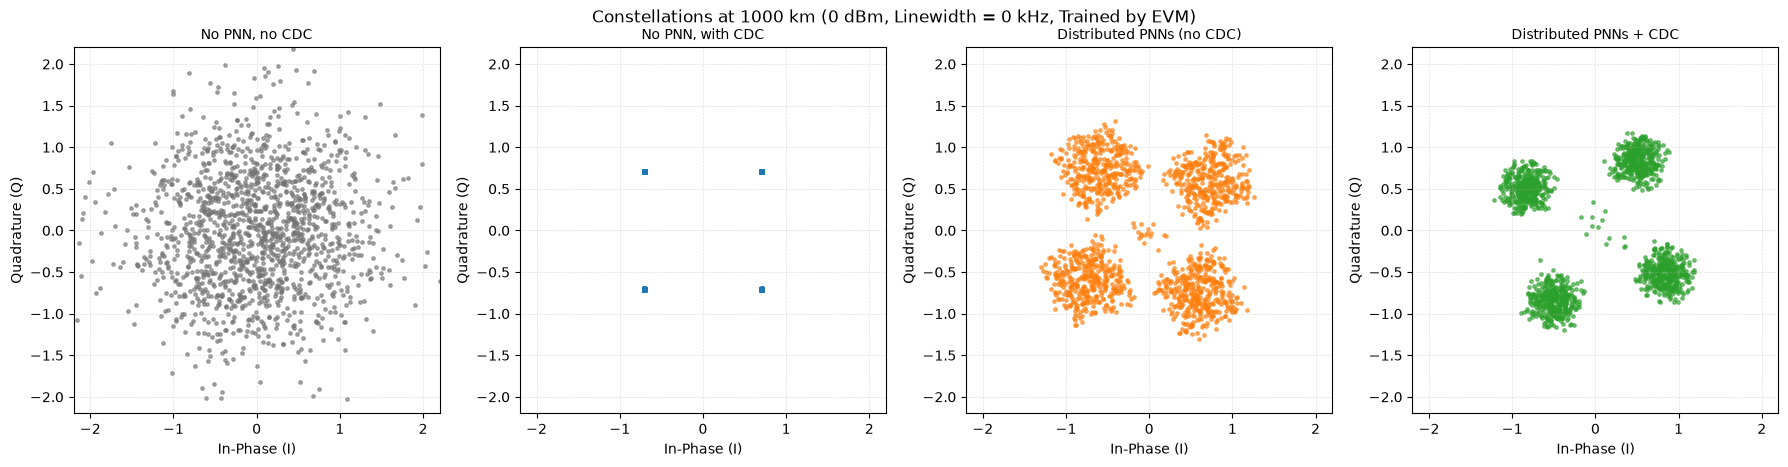

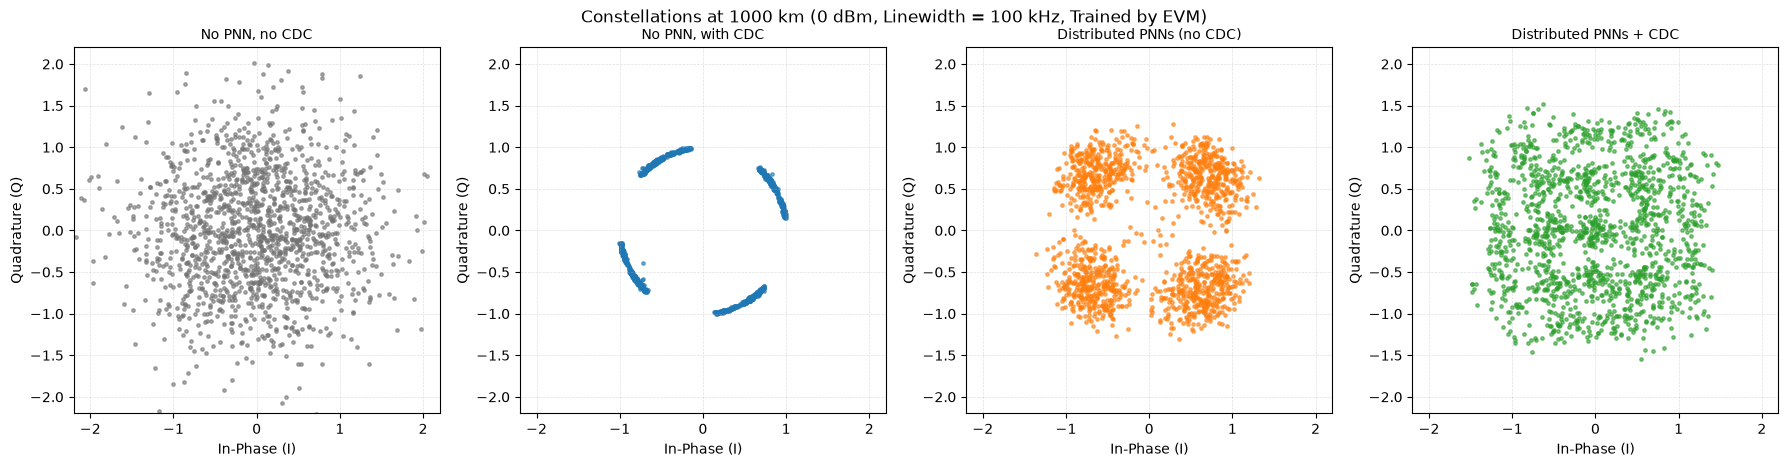

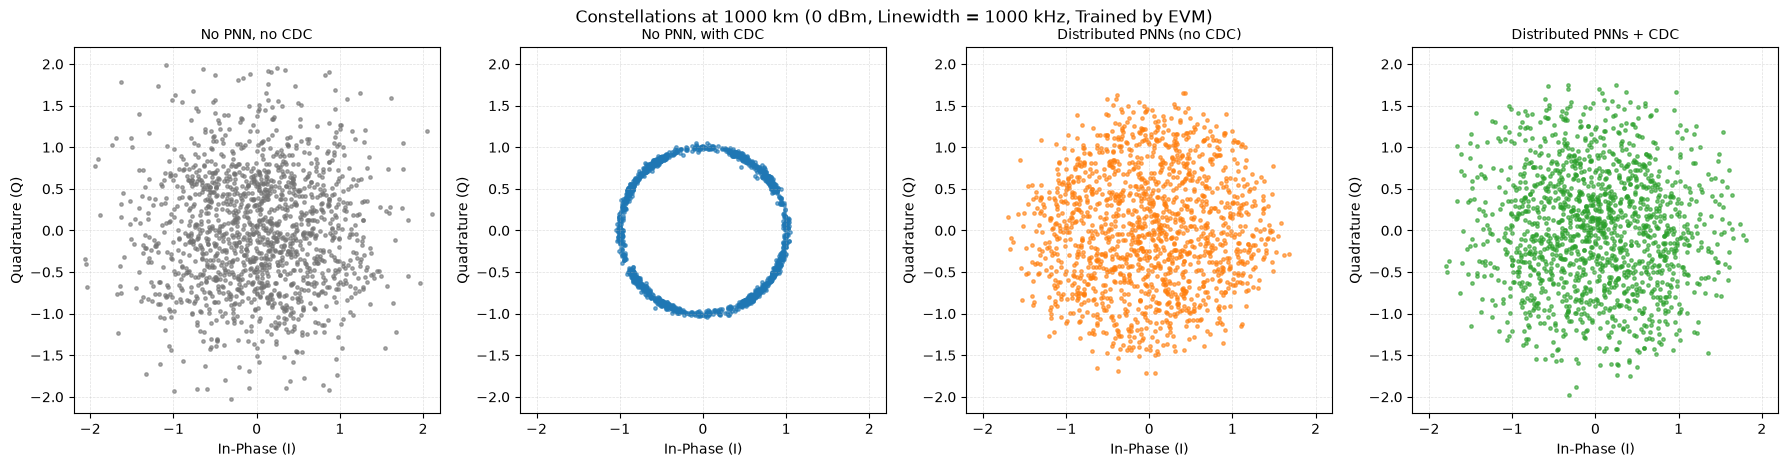

In [9]:
for lw_key in [0.0, 100e3, 1e6]:
    if lw_key not in constellations_1000km:
        continue
    c_data = constellations_1000km[lw_key]
    
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
    scenarios = [
        ('no_pnn_no_cdc', 'No PNN, no CDC', '0.45'),
        ('no_pnn_with_cdc', 'No PNN, with CDC', 'tab:blue'),
        ('mult_pnn_no_cdc', 'Distributed PNNs (no CDC)', 'tab:orange'),
        ('mult_pnn_joint_cdc', 'Distributed PNNs + CDC', 'tab:green'),
    ]
    
    n_plot = min(1500, len(c_data['no_pnn_no_cdc']))
    for ax, (key, title, color) in zip(axes, scenarios):
        syms = c_data[key][:n_plot]
        norm = np.sqrt(np.mean(np.abs(syms)**2) + 1e-30)
        s_norm = syms / norm
        ax.scatter(np.real(s_norm), np.imag(s_norm), s=6, alpha=0.6, color=color)
        ax.set_title(title, fontsize=10)
        ax.set_xlabel('In-Phase (I)')
        ax.set_ylabel('Quadrature (Q)')
        ax.set_xlim([-2.2, 2.2])
        ax.set_ylim([-2.2, 2.2])
        ax.grid(True, linestyle='--', alpha=0.4)
        ax.set_aspect('equal')
        
    fig.suptitle(f'Constellations at 1000 km (0 dBm, Linewidth = {lw_key/1e3:g} kHz, Trained by {PSO_OBJECTIVE})', fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'mult_pnn_constelacoes_1000km_lw_{int(lw_key/1e3)}k.png', dpi=250)
    plt.show()


## 9. Summary of Findings

1. **Standalone Optical PNNs vs. Digital CDC**:
   * Evaluates the extent to which in-line distributed optical filtering can mitigate chromatic dispersion along the fiber spans without digital post-compensation.
2. **Joint Equalization (Distributed PNNs + Digital CDC)**:
   * Assesses whether in-line optical equalizers enhance signal quality and lower the required digital DSP burden at the receiver.
3. **EVM vs. BER Objective**:
   * Demonstrates the continuous guidance provided by EVM-based optimization across the PSO iterations.
4. **Nonlinear Tolerance**:
   * Analyzes whether distributed analog filtering helps prevent nonlinear Kerr phase accumulation across multiple spans.
